In [22]:
# ===== PPI aggregate model rankings (from constraint_sweep workbooks) =====
import os
import numpy as np
import pandas as pd

# Configure
PATH = "../../.."  # <-- set this
DATASETS = ["NCT", "PANDA", "PanNuke", "PatchCamelyon"]  # adjust if needed

# --- helper (put above the loop) ---
def add_mean_row_col(df, mean_label="Mean"):
    base = df.copy()
    # Guard against existing "Mean" from prior runs
    if mean_label in base.columns:
        base = base.drop(columns=[mean_label])
    if mean_label in base.index:
        base = base.drop(index=[mean_label])

    row_means  = base.mean(axis=1, numeric_only=True)            # per-perturbation
    col_means  = base.mean(axis=0, numeric_only=True)            # per-model
    grand_mean = float(np.nanmean(base.to_numpy()))              # overall

    out = base.copy()
    out[mean_label] = row_means                                  # Mean column
    out.loc[mean_label] = list(col_means) + [grand_mean]         # Mean row (+ corner)
    return out


def _extract_mean_row(df, label="Mean"):
    """
    Return a Series where index = model names, values = the row labeled `label`.
    Works whether 'Mean' is an index value or lives in the first column.
    Non-numeric cells become NaN.
    """
    # case 1: 'Mean' is already an index value
    try:
        idx = df.index.astype(str).str.strip().str.lower()
        if (idx == label.lower()).any():
            row = df.loc[idx == label.lower()].iloc[0]
            return pd.to_numeric(row, errors="coerce")
    except Exception:
        pass

    # case 2: the first column holds row labels (e.g., 'Unnamed: 0')
    first = df.columns[0]
    mask = df[first].astype(str).str.strip().str.lower() == label.lower()
    if mask.any():
        row = df.loc[mask].iloc[0].drop(labels=[first], errors="ignore")
        return pd.to_numeric(row, errors="coerce")

    raise KeyError("Could not find a row labeled 'Mean' in the sheet.")

def read_ppi_for_dataset(ds):
    """
    Returns a DataFrame with columns: dataset, model, ppi_mean, ppi_std, rank
    Rank uses 'competition' style: ties share the same rank; next rank is skipped (method='min').
    """
    xlsx = os.path.join(PATH, "Stats", ds, "constraint_sweep", "ppi_aggregate.xlsx")
    if not os.path.isfile(xlsx):
        raise FileNotFoundError(f"Missing: {xlsx}")

    # Read sheets
    mean_df = pd.read_excel(xlsx, sheet_name="ppi_mean", header=0)
    std_df  = pd.read_excel(xlsx, sheet_name="ppi_std",  header=0)

    s_mean = _extract_mean_row(mean_df)  # index = model names
    s_std  = _extract_mean_row(std_df)

    # union of models present on either sheet
    models = sorted(set(s_mean.index.astype(str)).union(s_std.index.astype(str)))

    rows = []
    for m in models:
        rows.append({
            "dataset": ds,
            "model": m,
            "ppi_mean": float(s_mean.get(m, np.nan)) if pd.notna(s_mean.get(m, np.nan)) else np.nan,
            "ppi_std":  float(s_std.get(m, np.nan))  if pd.notna(s_std.get(m, np.nan))  else np.nan,
        })
    df = pd.DataFrame(rows)

    # rank by higher PPI is better (competition ranking via method='min')
    if df["ppi_mean"].notna().any():
        df["rank"] = df["ppi_mean"].rank(ascending=False, method="min")
    else:
        df["rank"] = np.nan

    return df

# Collect per-dataset ranks
per_ds = []
for ds in DATASETS:
    try:
        per_ds.append(read_ppi_for_dataset(ds))
    except Exception as e:
        print(f"Skipped {ds}: {e}")

if not per_ds:
    raise RuntimeError("No datasets processed; check paths and filenames.")

per_ds_df = pd.concat(per_ds, ignore_index=True)

# Aggregate across datasets (average of available values; decimals allowed)
agg = (
    per_ds_df
    .groupby("model", as_index=False)
    .agg(
        avg_PPI=("ppi_mean", "mean"),
        avg_std=("ppi_std", "mean"),
        avg_rank=("rank", "mean")
    )
    .sort_values("avg_rank", ascending=True)
)

# Order columns as requested
agg = agg[["avg_rank", "model", "avg_PPI", "avg_std"]]

# Save Excel with two sheets
out_xlsx = os.path.join(PATH, "Stats", "PPI_aggregate_model_rankings.xlsx")
with pd.ExcelWriter(out_xlsx) as xw:
    agg.to_excel(xw, sheet_name="AGGREGATE_RANKINGS", index=False, float_format="%.6f")
    per_ds_df.sort_values(["dataset", "rank", "ppi_mean"], ascending=[True, True, False]) \
             .to_excel(xw, sheet_name="PER_DATASET_RANKS", index=False, float_format="%.6f")

print(f"Saved:\n- {out_xlsx}")

Saved:
- Stats\PPI_aggregate_model_rankings.xlsx


In [23]:
# ===== Cell 1: Config & imports =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Root where Stats/ lives
PATH = "../../.."  # <-- set this

# Datasets to include in the 2×2 (left-to-right, top-to-bottom)
DATASETS = ["NCT", "PanNuke", "PANDA", "PatchCamelyon"]

# PPI workbook info
XLSX_REL = os.path.join("constraint_sweep", "ppi_aggregate.xlsx")
SHEET_MEAN = "ppi_mean"  # read this sheet and drop the 'Mean' row

# Plot options
ANNOTATE = False             # write numeric values in each cell
MODEL_LABEL_ROT = 60        # rotation for model names on top
FIXED_SCALE = (None, None)  # (vmin, vmax); set e.g. (0.2, 1.0) or leave (None, None) for global min/max

# Output
OUT_DIR = os.path.join(PATH, "Stats", "PPI")
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 120


In [24]:
# ===== Cell 2: Helpers =====

def read_ppi_matrix(dataset_name: str) -> pd.DataFrame:
    """
    Read Stats/{dataset}/constraint_sweep/ppi_aggregate.xlsx::ppi_mean,
    drop the 'Mean' row, return a DataFrame:
        rows   = perturbations (e.g., blur, crop, ...),
        cols   = model names,
        values = PPI means (floats).
    Handles cases where the perturbation labels are in the first column.
    """
    xlsx = os.path.join(PATH, "Stats", dataset_name, XLSX_REL)
    if not os.path.isfile(xlsx):
        raise FileNotFoundError(f"Missing: {xlsx}")

    # Try with first column as index; fall back to default then set index manually
    try:
        df = pd.read_excel(xlsx, sheet_name=SHEET_MEAN, header=0, index_col=0)
    except Exception:
        df = pd.read_excel(xlsx, sheet_name=SHEET_MEAN, header=0)
        df = df.set_index(df.columns[0])

    # Drop the 'Mean' row (case-insensitive, trimmed)
    # idx_norm = df.index.astype(str).str.strip().str.lower()
    # df = df.loc[idx_norm != "mean"].copy()

    # Coerce all values to numeric
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.sort_index(key=lambda s: s.astype(str).str.lower())

    return df  # perturbations × models

# 1) Load per-dataset matrices
MATS = {}              # {dataset: DataFrame (perturbations × models)}
ALL_MODELS = set()

for ds in DATASETS:
    mat_df = read_ppi_matrix(ds)
    MATS[ds] = mat_df
    ALL_MODELS.update(mat_df.columns.astype(str))

# 2) Align columns (models) globally so all subplots share the same column order
MODEL_LIST = sorted(ALL_MODELS)

for ds in DATASETS:
    df = MATS[ds]
    # reindex columns to the global model list (NaN where missing)
    MATS[ds] = df.reindex(columns=MODEL_LIST)


C:\Users\Dhyey\AppData\Local\Temp\ipykernel_21532\4204996931.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("viridis").copy()  # so we can set a 'bad' color


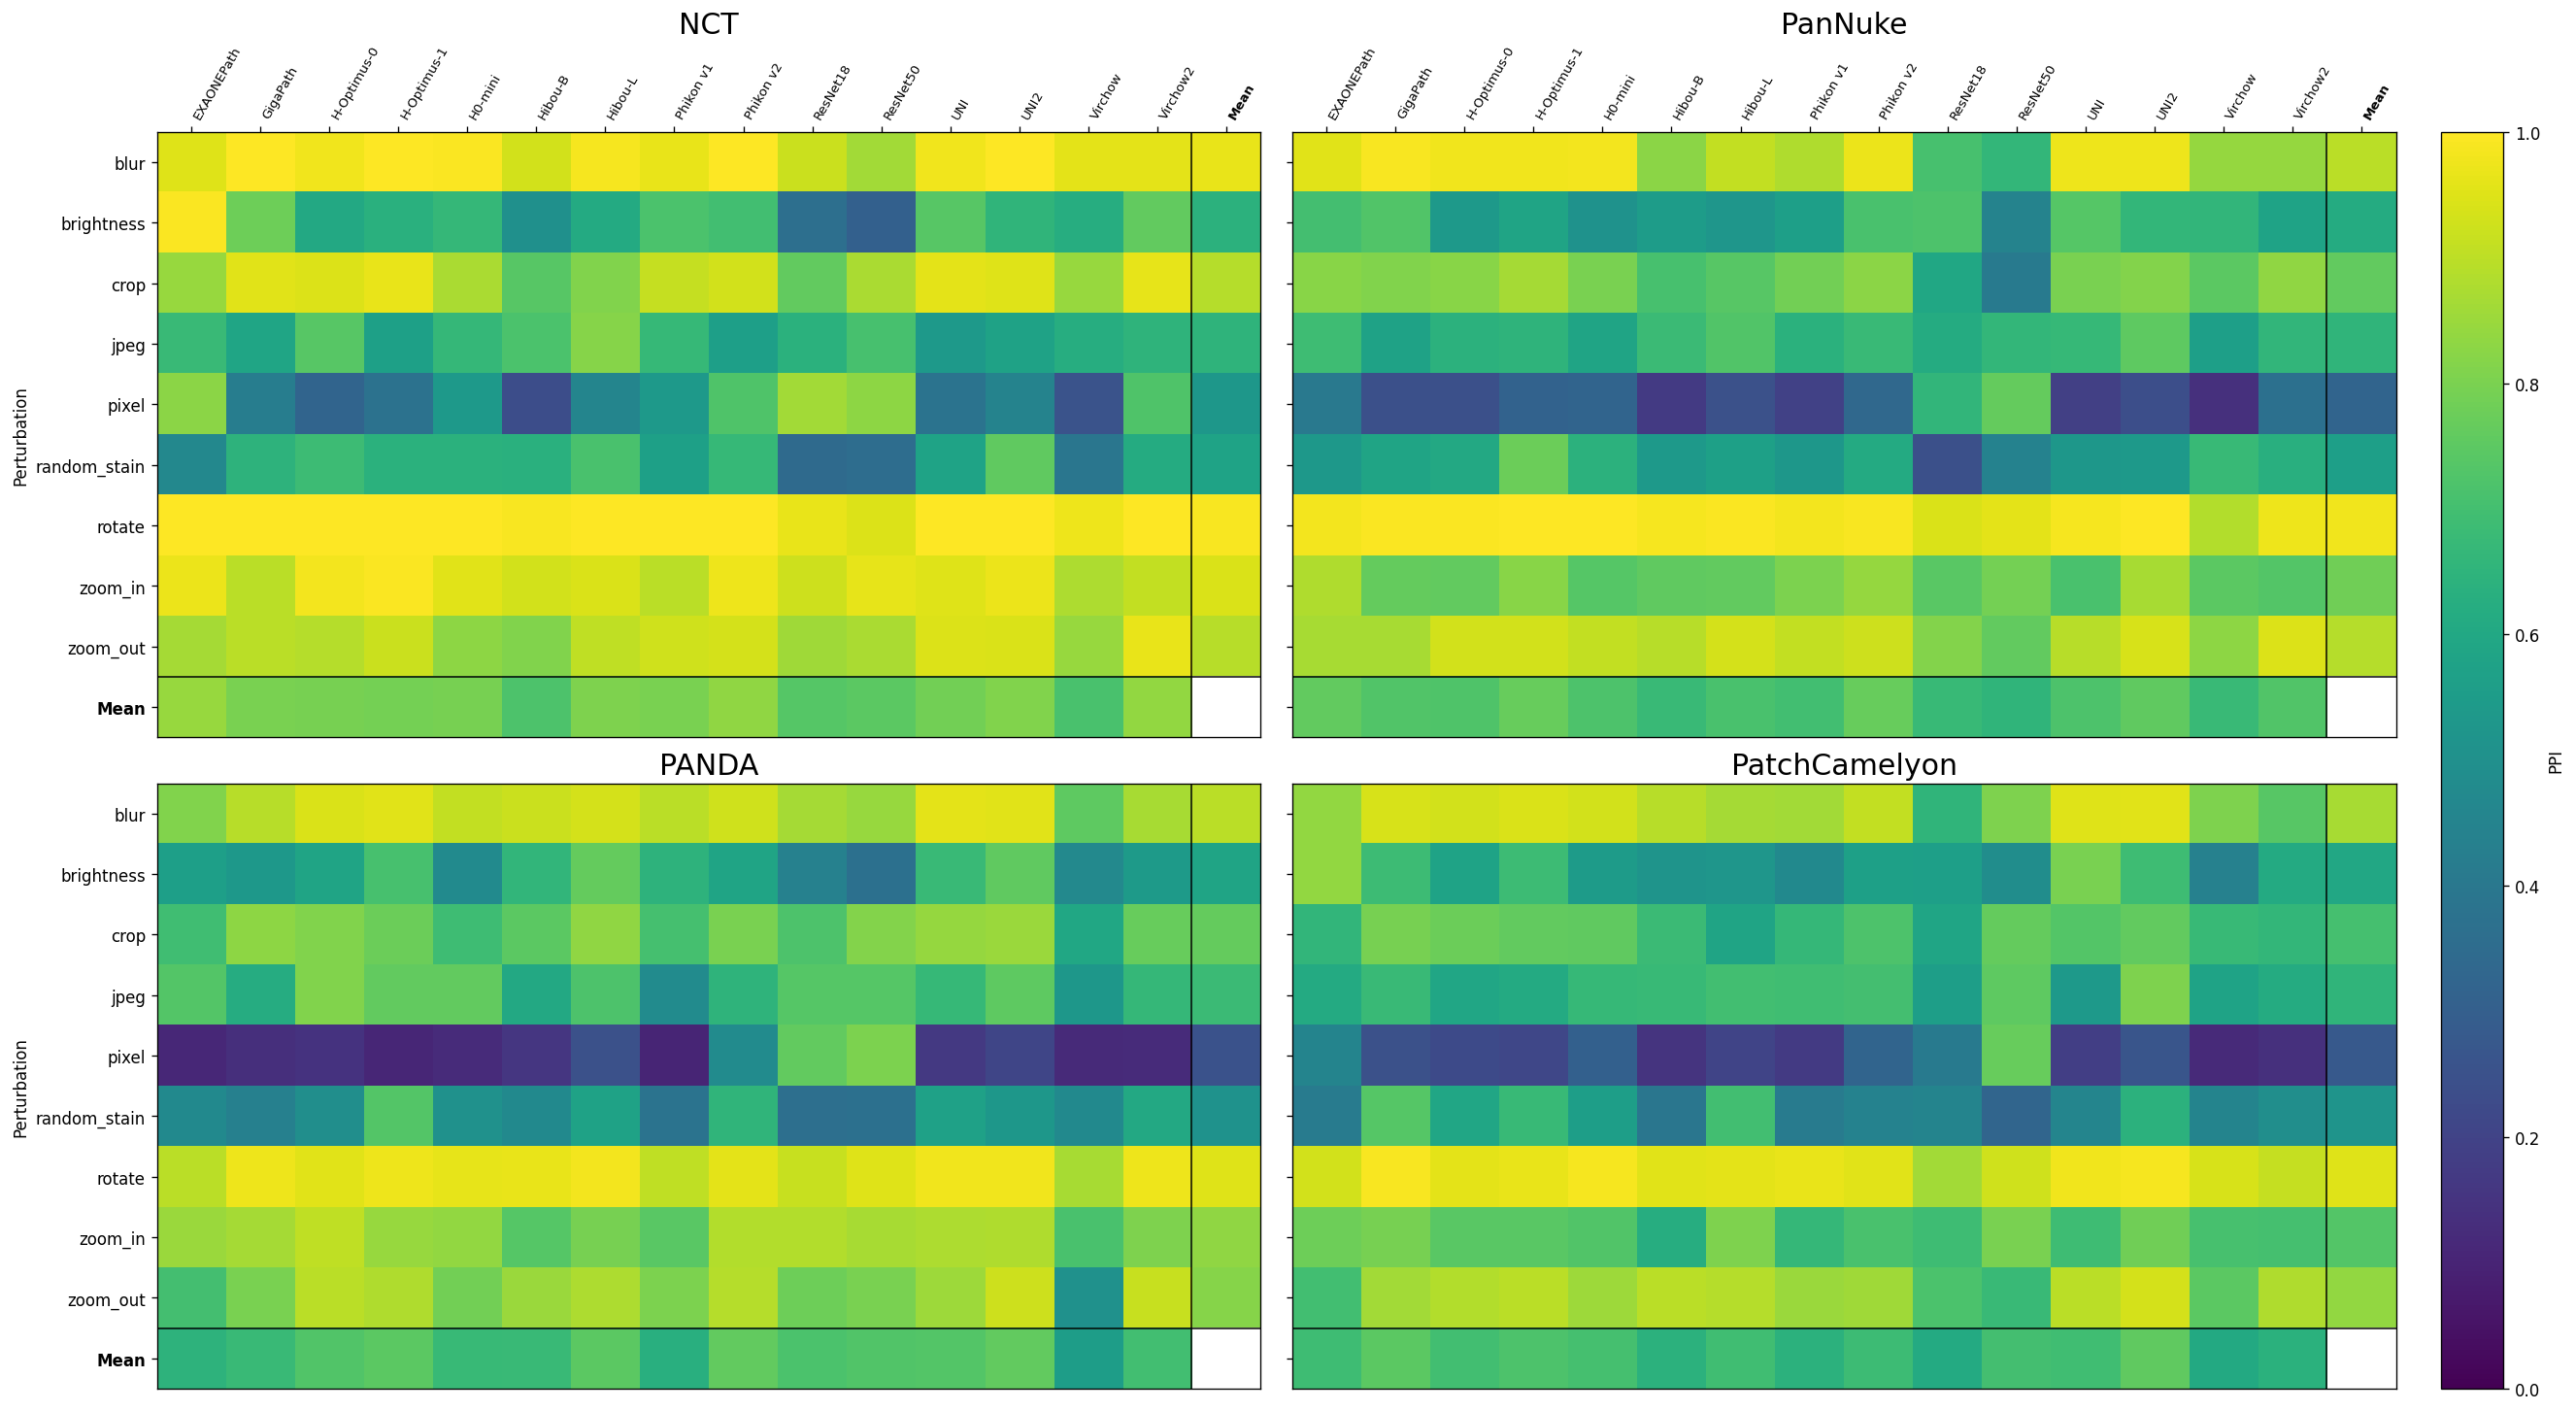

In [25]:
# Figure
fig, axes = plt.subplots(2, 2, figsize=(22, 12), constrained_layout=True)
axes = axes.ravel()

TITLE_FONTSIZE = 18  # big dataset title
XTICK_FONTSIZE = 8
YTICK_FONTSIZE = 10

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

cmap = plt.cm.get_cmap("viridis").copy()  # so we can set a 'bad' color
cmap.set_bad(color="white")               # bottom-right (NaN) cell shows as blank
norm = Normalize(vmin=0.0, vmax=1.0)




for idx, (ax, ds) in enumerate(zip(axes, DATASETS)):
    df = MATS[ds]
    if df.empty:
        ax.axis("off")
        ax.set_title(f"{ds} (no data)", fontsize=TITLE_FONTSIZE, fontweight="bold", pad=22)
        continue

    # Add Mean column & Mean row (with grand mean in corner)
    df_plot = add_mean_row_col(df, mean_label="Mean")

    # Prepare array; blank the bottom-right "Mean×Mean" corner
    arr = df_plot.to_numpy().astype(float)
    arr[-1, -1] = np.nan
    arr_masked = np.ma.masked_invalid(arr)

    # Heatmap
    im = ax.imshow(arr_masked, aspect="auto", cmap=cmap, norm=norm)

    # X ticks (models + 'Mean'): show labels only on TOP row
    ax.set_xticks(np.arange(df_plot.shape[1]))
    if idx < 2:  # top row
        ax.set_xticklabels(df_plot.columns.tolist(), rotation=MODEL_LABEL_ROT,
                           ha="left", fontsize=XTICK_FONTSIZE)
        ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
    else:        # bottom row: hide model labels entirely
        ax.set_xticklabels([])
        ax.tick_params(axis="x", top=False, labeltop=False, bottom=False, labelbottom=False)

    # Y ticks (perturbations + 'Mean')
    ax.set_yticks(np.arange(df_plot.shape[0]))
    if idx % 2 == 0:   # left column: show labels + ylabel
        ax.set_yticklabels(df_plot.index.tolist(), fontsize=YTICK_FONTSIZE)
        ax.set_ylabel("Perturbation")
    else:              # right column: hide labels
        ax.set_yticklabels([])
        ax.tick_params(axis="y", left=True, labelleft=False)

    # Title
    ax.set_title(ds, fontsize=TITLE_FONTSIZE)

    # Separator LINES: between the main block and the Mean row/column
    nrows, ncols = df_plot.shape
    ax.axhline(nrows - 1.5, color="k", lw=0.9)  # between last data row and Mean row
    ax.axvline(ncols - 1.5, color="k", lw=0.9)  # between last data col and Mean col

    # Optional: annotate values (skip NaN corner automatically)
    if ANNOTATE:
        for i in range(nrows):
            for j in range(ncols):
                val = arr[i, j]
                if np.isnan(val):
                    continue
                tcolor = "black" if norm(val) > 0.6 else "white"
                ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=8, color=tcolor)

    # Optional: bold the 'Mean' tick labels (left/top panels only where labels are visible)
    if idx < 2:
        xt = ax.get_xticklabels()
        if xt: xt[-1].set_fontweight("bold")
    if idx % 2 == 0:
        yt = ax.get_yticklabels()
        if yt: yt[-1].set_fontweight("bold")


# Hide any unused axes if fewer than 4 datasets
for k in range(len(DATASETS), 4):
    axes[k].axis("off")

# Shared colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axes, orientation="vertical", fraction=0.03, pad=0.02)
cbar.set_label("PPI")